In [ ]:
import ت
import numpy
from pathlib import Path 
import csv

In [5]:
csv_path=Path(r'E:\lifeguardDron\datasets_inventory.csv')
if not csv_path.exists():
    print(f"File not found: {csv_path}")
else:
    with csv_path.open("r", encoding="utf-8-sig", newline="") as f:
        reader = csv.DictReader(f)

        print("Columns:")
        print(reader.fieldnames)

        print("\nFirst 10 rows:")
        for i, row in enumerate(reader):
            if i == 10:
                break
            print(f"\n--- Row {i + 1} ---")
            for key, value in row.items():
                print(f"{key}: {value}")


Columns:
['name', 'intended_use', 'category', 'task', 'viewpoint', 'environment', 'classes', 'annotation_format', 'images', 'annotations', 'license', 'license_attribution', 'access', 'official_url', 'direct_download_url', 'download_size', 'storage_path', 'suitability_detection', 'suitability_tracking', 'suitability_distress', 'suitability_rescue_equipment', 'status', 'notes']

First 10 rows:

--- Row 1 ---
name: SeaDronesSee ODv2 (HF mirror)
intended_use: Primary aerial swimmer/person-in-water detection (stage 2 detector)
category: aerial
task: object detection
viewpoint: aerial/drone
environment: open water / lake
classes: swimmer, boat, jetski, life_saving_appliances, buoy
annotation_format: YOLO (COCO original)
images: 8930 train / 1547 val
annotations: 57760 boxes train / 9630 boxes val
license: n/a
license_attribution: CC0 1.0 (code MIT)
access: free (no registration needed for HF mirror; registration only for official benchmark server)
official_url: https://seadronessee.cs.uni-tu

In [7]:


from pathlib import Path
import csv
import os

PROJECT = Path(r"E:\lifeguardDron")

print("=== 1. Project folder ===")
print("Exists:", PROJECT.exists())
print("Path:", PROJECT)

print("\n=== 2. Expected files ===")
expected = [
    "scripts/run_pipeline.py",
    "scripts/01_dataset_audit.py",
    "scripts/02_validate_annotations.py",
    "scripts/03_prepare_detection_dataset.py",
    "scripts/04_inspect_video_dataset.py",
    "scripts/05_extract_video_frames.py",
    "scripts/06_visualize_annotations.py",
    "datasets_inventory.csv",
]

for relative_path in expected:
    path = PROJECT / relative_path
    if path.is_file():
        print(f"[FOUND] {relative_path} | {path.stat().st_size:,} bytes")
    else:
        print(f"[MISSING] {relative_path}")

print("\n=== 3. Project root contents ===")
if PROJECT.is_dir():
    for item in sorted(PROJECT.iterdir()):
        kind = "DIR " if item.is_dir() else "FILE"
        print(f"[{kind}] {item.name}")

print("\n=== 4. Scripts folder contents ===")
scripts_dir = PROJECT / "scripts"

if scripts_dir.is_dir():
    for item in sorted(scripts_dir.iterdir()):
        print(f"{item.name} | {item.stat().st_size:,} bytes")
else:
    print("Scripts folder does not exist yet.")




=== 1. Project folder ===
Exists: True
Path: E:\lifeguardDron

=== 2. Expected files ===
[MISSING] scripts/run_pipeline.py
[FOUND] scripts/01_dataset_audit.py | 9,600 bytes
[MISSING] scripts/02_validate_annotations.py
[MISSING] scripts/03_prepare_detection_dataset.py
[MISSING] scripts/04_inspect_video_dataset.py
[MISSING] scripts/05_extract_video_frames.py
[MISSING] scripts/06_visualize_annotations.py
[FOUND] datasets_inventory.csv | 7,639 bytes

=== 3. Project root contents ===
[DIR ] .kilo
[FILE] 01_dataset_audit.ps1.ipynb
[FILE] DATASET_MANIFEST.md
[DIR ] datasets
[FILE] datasets_inventory.csv
[DIR ] reports
[DIR ] scripts

=== 4. Scripts folder contents ===
01_dataset_audit.py | 9,600 bytes
__pycache__ | 0 bytes
common.py | 7,823 bytes
config.yaml | 3,051 bytes


In [8]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not detected")

PyTorch version: 2.11.0+cu128
CUDA available: True
CUDA version: 12.8
GPU: NVIDIA GeForce GTX 1650


In [9]:
from pathlib import Path
import yaml

PROJECT = Path(r"E:\lifeguardDron")
DATASET_YAML = (
    PROJECT
    / "data_prepared"
    / "detection"
    / "SeaDronesSee_ODv2"
    / "dataset.yaml"
)

print("Dataset YAML exists:", DATASET_YAML.exists())

if DATASET_YAML.exists():
    print(DATASET_YAML.read_text(encoding="utf-8"))

    config = yaml.safe_load(DATASET_YAML.read_text(encoding="utf-8"))
    print("\nDataset root:", config.get("path"))
    print("Classes:", config.get("names"))

Dataset YAML exists: True
# Auto-generated by 03_prepare_detection_dataset.py
path: E:/lifeguardDron/data_prepared/detection/SeaDronesSee_ODv2
train: images/train
val: images/val
nc: 5
names:
  0: swimmer
  1: boat
  2: jetski
  3: life_saving_appliances
  4: buoy


Dataset root: E:/lifeguardDron/data_prepared/detection/SeaDronesSee_ODv2
Classes: {0: 'swimmer', 1: 'boat', 2: 'jetski', 3: 'life_saving_appliances', 4: 'buoy'}


In [10]:
%pip install ultralytics

                                              0.0/1.4 MB ? eta -:--:--
                                              0.0/1.4 MB 1.4 MB/s eta 0:00:02
                                              0.0/1.4 MB 1.4 MB/s eta 0:00:02
     --                                       0.1/1.4 MB 491.5 kB/s eta 0:00:03
     ---                                      0.1/1.4 MB 656.4 kB/s eta 0:00:03
     ----                                     0.1/1.4 MB 655.8 kB/s eta 0:00:02
     -----                                    0.2/1.4 MB 737.3 kB/s eta 0:00:02
     ------                                   0.2/1.4 MB 724.0 kB/s eta 0:00:02
     -------                                  0.3/1.4 MB 741.6 kB/s eta 0:00:02
     --------                                 0.3/1.4 MB 761.4 kB/s eta 0:00:02
     ---------                                0.3/1.4 MB 749.8 kB/s eta 0:00:02
     ----------                               0.4/1.4 MB 782.8 kB/s eta 0:00:02
     -----------                              0.4/1.4


[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path as FilePath
import torch
from ultralytics import YOLO

In [3]:
PROJECT = FilePath(r"E:\lifeguardDron")
dataset=PROJECT/'data_prepared' /'detection'/'SeaDronesSee_ODv2'/'dataset.yaml'

print("Dataset Exists :",dataset.exists())
print("Cuda Available :",torch.cuda.is_available())

Dataset Exists : True
Cuda Available : True


In [5]:
model = YOLO("yolo11n.pt")

results = model.train(
    data=str(dataset),
    epochs=2,
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    project=str(PROJECT / "runs" / "detect"),
    name="seadrones_smoke_test",
    exist_ok=False,
    plots=False,
    save=True,
    amp=True,
    patience=2,
    seed=42,
)

print("Training finished.")
print("Results saved to:", PROJECT / "runs" / "detect" / "seadrones_smoke_test")

Ultralytics 8.4.182  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=seadron

In [11]:

from pathlib import Path

PROJECT = Path(r"E:\lifeguardDron")

dataset = (
    PROJECT / "data_prepared" / "detection"
    / "SeaDronesSee_ODv2" / "dataset.yaml"
)

BEST = (
    PROJECT / "runs" / "detect"
    / "seadrones_smoke_test" / "weights" / "best.pt"
)

print("Dataset exists:", dataset.exists())
print("Weights exist:", BEST.exists())

assert dataset.exists(), f"Dataset not found: {dataset}"
assert BEST.exists(), f"Best weights not found: {BEST}"

review_model = YOLO(str(BEST))

metrics = review_model.val(
    data=str(dataset),
    imgsz=640,
    batch=4,
    device=0,
    plots=True,
    project=str(PROJECT / "runs" / "evaluation"),
    name="baseline_review",
    exist_ok=False,
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Review folder:", PROJECT / "runs" / "evaluation" / "baseline_review")


Dataset exists: True
Weights exist: True
Ultralytics 8.4.182  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1079.7±951.8 MB/s, size: 830.8 KB)
val: Scanning E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\labels\val.cache... 1547 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1547/1547 307.1Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 387/387 4.3it/s 1:290.3ssss1
                   all       1547       9630       0.85      0.527      0.558      0.284
               swimmer       1286       6206      0.722      0.588      0.577      0.204
                  boat        915       2214      0.893      0.848       0.89      0.533
                jetski        320        320      0.693      0.775      0.761      0.384
life_saving_appliances     

In [10]:
import sys
from pathlib import Path
from ultralytics import YOLO

print("Python:", sys.executable)
print("Ultralytics imported successfully")

Python: c:\Users\tarek\AppData\Local\Programs\Python\Python311\python.exe
Ultralytics imported successfully


In [12]:
from pathlib import Path
from collections import Counter

PROJECT = Path(r"E:\lifeguardDron")
BASE = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2"

class_names = {
    0: "swimmer",
    1: "boat",
    2: "jetski",
    3: "life_saving_appliances",
    4: "buoy",
}

for split in ["train", "val"]:
    counts = Counter()
    label_dir = BASE / "labels" / split

    for file in label_dir.glob("*.txt"):
        for line in file.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if parts:
                try:
                    class_id = int(parts[0])
                    counts[class_id] += 1
                except ValueError:
                    pass

    print(f"\n{split.upper()}")
    for class_id, name in class_names.items():
        print(f"{name:25s}: {counts[class_id]}")


TRAIN
swimmer                  : 37096
boat                     : 13022
jetski                   : 2330
life_saving_appliances   : 923
buoy                     : 4389

VAL
swimmer                  : 6206
boat                     : 2214
jetski                   : 320
life_saving_appliances   : 330
buoy                     : 560


In [13]:

from pathlib import Path
from collections import defaultdict
from ultralytics import YOLO
import numpy as np

PROJECT = Path(r"E:\lifeguardDron")
DATASET_DIR = (
    PROJECT / "data_prepared" / "detection"
    / "SeaDronesSee_ODv2"
)
BEST = (
    PROJECT / "runs" / "detect" / "seadrones_smoke_test"
    / "weights" / "best.pt"
)

model = YOLO(str(BEST))

# Collect validation predictions at a low confidence threshold
results = model.predict(
    source=str(DATASET_DIR / "images" / "val"),
    imgsz=640,
    batch=4,
    device=0,
    conf=0.001,
    iou=0.7,
    stream=True,
    verbose=False,
)

counts = defaultdict(int)

for result in results:
    if result.boxes is None or len(result.boxes) == 0:
        continue

    for cls_id, confidence in zip(
        result.boxes.cls.cpu().numpy().astype(int),
        result.boxes.conf.cpu().numpy(),
    ):
        if cls_id == 3:
            counts["all"] += 1
            if confidence >= 0.001:
                counts["conf_001"] += 1
            if confidence >= 0.01:
                counts["conf_01"] += 1
            if confidence >= 0.10:
                counts["conf_10"] += 1
            if confidence >= 0.25:
                counts["conf_25"] += 1
            if confidence >= 0.50:
                counts["conf_50"] += 1

print("Predictions for life_saving_appliances:")
for key, value in counts.items():
    print(f"{key}: {value}")


Predictions for life_saving_appliances:
all: 42
conf_001: 42
conf_01: 22
conf_10: 13
conf_25: 4


Validation images containing class 3: 191


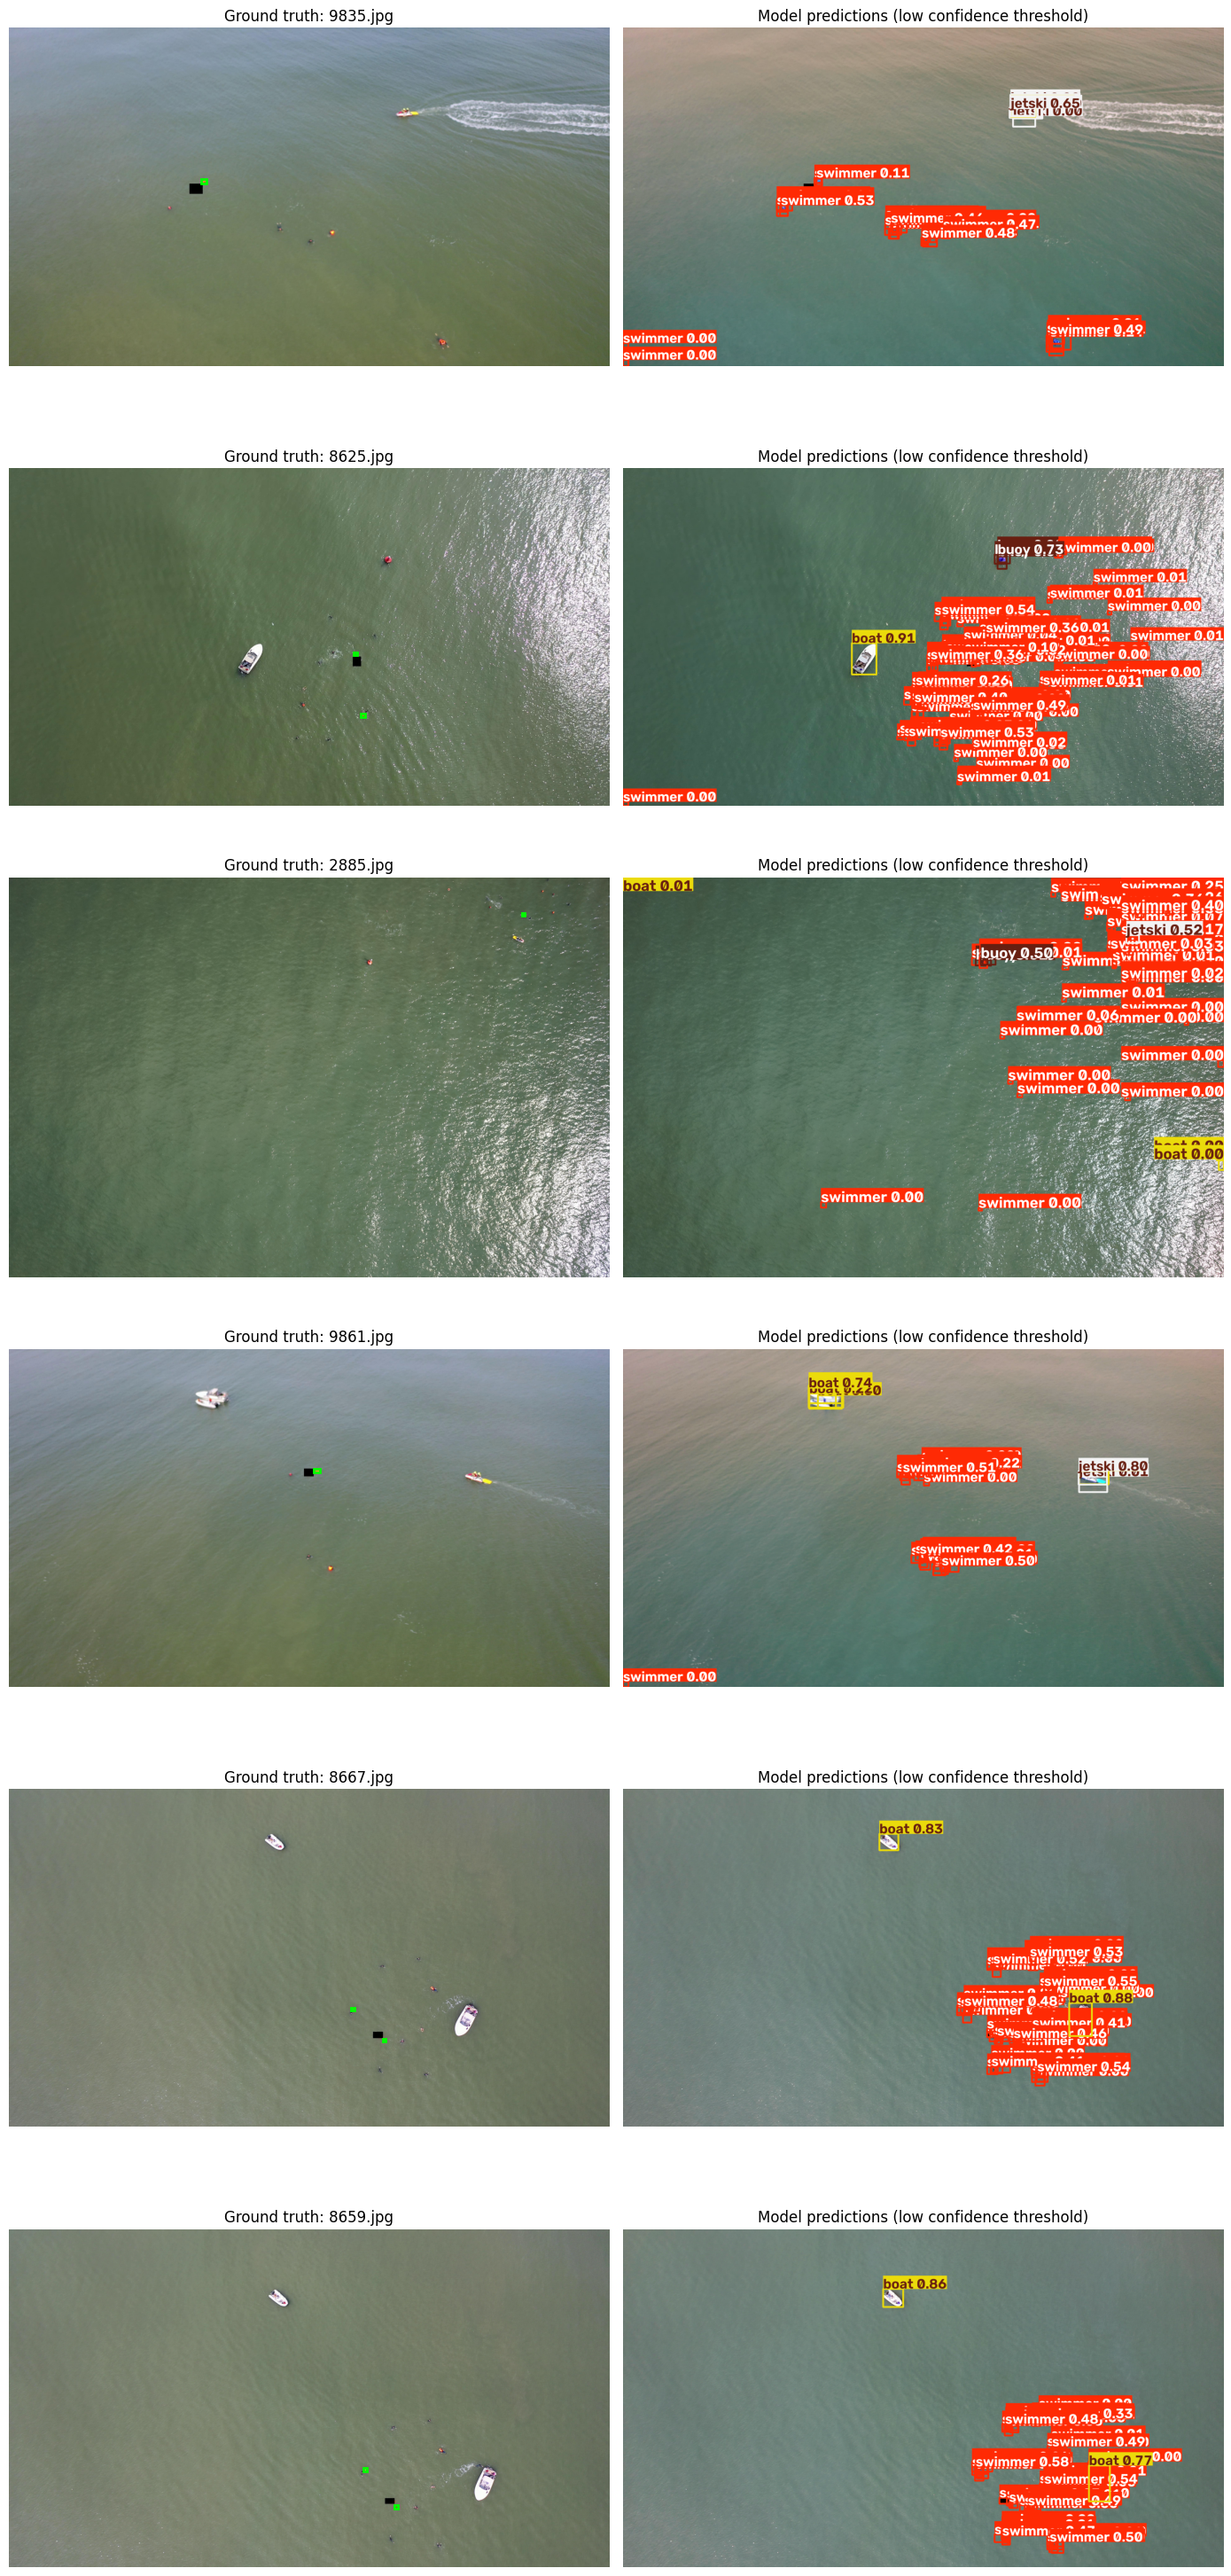

In [14]:

from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

PROJECT = Path(r"E:\lifeguardDron")
DATA = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2"
BEST = PROJECT / "runs" / "detect" / "seadrones_smoke_test" / "weights" / "best.pt"

images_dir = DATA / "images" / "val"
labels_dir = DATA / "labels" / "val"

# Find validation images whose labels contain class 3
candidates = []
for label_file in labels_dir.glob("*.txt"):
    lines = label_file.read_text(encoding="utf-8").splitlines()
    if any(line.split() and line.split()[0] == "3" for line in lines):
        image_path = next(
            (images_dir / f"{label_file.stem}{ext}"
             for ext in (".jpg", ".jpeg", ".png", ".webp")
             if (images_dir / f"{label_file.stem}{ext}").exists()),
            None
        )
        if image_path:
            candidates.append((image_path, label_file))

print("Validation images containing class 3:", len(candidates))
random.seed(42)
samples = random.sample(candidates, min(6, len(candidates)))

model = YOLO(str(BEST))

fig, axes = plt.subplots(len(samples), 2, figsize=(14, 5 * len(samples)))
if len(samples) == 1:
    axes = [axes]

for i, (image_path, label_path) in enumerate(samples):
    # Ground-truth image with YOLO-format labels
    image = Image.open(image_path).convert("RGB")
    w, h = image.size
    fig_gt = axes[i][0]
    fig_gt.imshow(image)

    for line in label_path.read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) != 5:
            continue
        cls_id, xc, yc, bw, bh = map(float, p)
        if int(cls_id) != 3:
            continue
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        rect = plt.Rectangle((x1, y1), bw * w, bh * h,
                             fill=False, edgecolor="lime", linewidth=2)
        fig_gt.add_patch(rect)

    fig_gt.set_title(f"Ground truth: {image_path.name}")
    fig_gt.axis("off")

    # Model predictions
    result = model.predict(
        source=str(image_path), imgsz=640, device=0,
        conf=0.001, verbose=False
    )[0]
    axes[i][1].imshow(result.plot())
    axes[i][1].set_title("Model predictions (low confidence threshold)")
    axes[i][1].axis("off")

plt.tight_layout()
plt.show()


In [15]:

from pathlib import Path
from ultralytics import YOLO

PROJECT = Path(r"E:\lifeguardDron")
DATASET = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2" / "dataset.yaml"
BEST = PROJECT / "runs" / "detect" / "seadrones_smoke_test" / "weights" / "best.pt"

model = YOLO(str(BEST))

for conf in [0.001, 0.01, 0.05, 0.10, 0.25]:
    metrics = model.val(
        data=str(DATASET),
        imgsz=640,
        batch=4,
        device=0,
        conf=conf,
        plots=False,
        verbose=False,
    )

    # Class index 3 = life_saving_appliances
    class_index = 3
    print(
        f"conf={conf:.3f} | "
        f"P={metrics.box.p[class_index]:.4f} | "
        f"R={metrics.box.r[class_index]:.4f} | "
        f"mAP50={metrics.box.ap50[class_index]:.4f}"
    )


Ultralytics 8.4.182  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1350.4±609.5 MB/s, size: 522.7 KB)
val: Scanning E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\labels\val.cache... 1547 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1547/1547  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 387/387 6.7it/s 58.0s<0.1ss4
                   all       1547       9630       0.85      0.527      0.558      0.284
Speed: 1.4ms preprocess, 6.4ms inference, 0.0ms loss, 2.4ms postprocess per image
conf=0.001 | P=1.0000 | R=0.0000 | mAP50=0.0998
Ultralytics 8.4.182  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0